In [2]:
library(tidyverse)

# ---------------- CONFIG ----------------
combined_path <- "/Users/ashleybelknap/Library/CloudStorage/OneDrive-TexasA&MAgriLife/Barboza Lab Shared/PCH_CaribouForage/NIR_CBforage/R files/combined_long.csv"
# -----------------------------------------

combined <- read_csv(combined_path, show_col_types = FALSE)

# Quick sanity check on load
message(sprintf("Loaded %s rows, %d unique samples",
                format(nrow(combined), big.mark = ","),
                n_distinct(combined$sample_id)))

glimpse(combined)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loaded 2,098,950 rows, 1998 unique samples



Rows: 2,098,950
Columns: 17
$ sample_id    <chr> "AB001", "AB001", "AB001", "AB001", "AB001", "AB001", "AB…
$ wavelength   <dbl> 400, 402, 404, 406, 408, 410, 412, 414, 416, 418, 420, 42…
$ source_file  <chr> "erva_spectra.csv", "erva_spectra.csv", "erva_spectra.csv…
$ intensity    <dbl> 0.4353449, 0.4556786, 0.4731230, 0.4864933, 0.5076650, 0.…
$ n_replicates <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, …
$ transect     <chr> "H", "H", "H", "H", "H", "H", "H", "H", "H", "H", "H", "H…
$ sampleid     <chr> "ERVA-10H", "ERVA-10H", "ERVA-10H", "ERVA-10H", "ERVA-10H…
$ s_num        <chr> "10", "10", "10", "10", "10", "10", "10", "10", "10", "10…
$ species      <chr> "ERVA", "ERVA", "ERVA", "ERVA", "ERVA", "ERVA", "ERVA", "…
$ dataset_type <chr> "calibration", "calibration", "calibration", "calibration…
$ ecoregion    <chr> "Brooks Range", "Brooks Range", "Brooks Range", "Brooks R…
$ pfg          <chr> "graminoid", "graminoid", "graminoid", "graminoid", "gram…
$ macroplot 

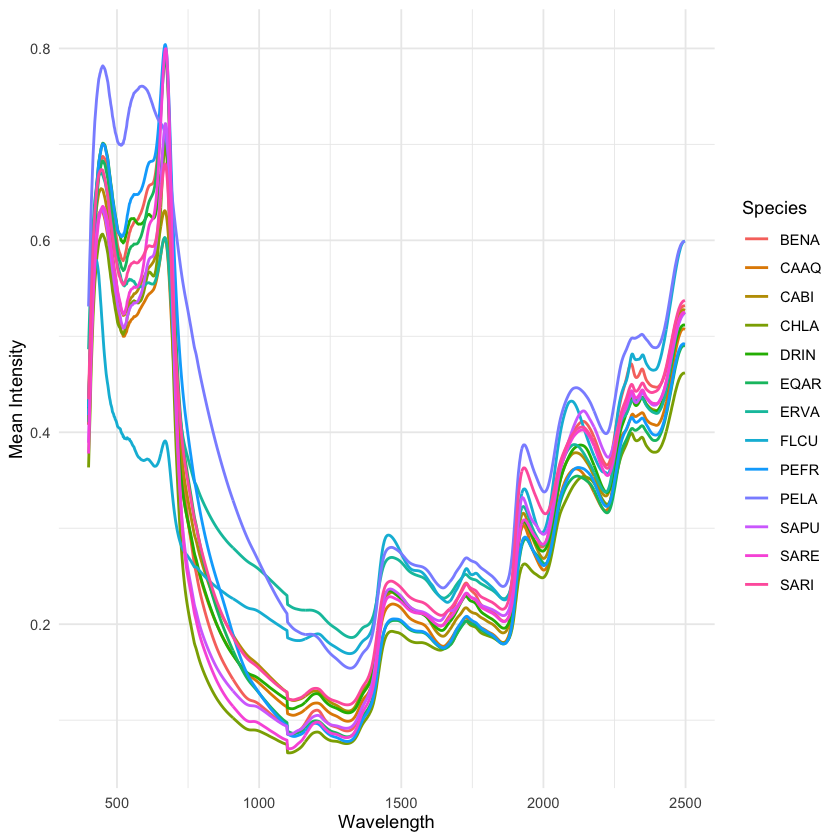

In [3]:
species_mean <- combined %>%
  group_by(species, wavelength) %>%     # replace 'species' with your actual column name
  summarize(mean_intensity = mean(intensity, na.rm = TRUE), .groups = "drop")

ggplot(species_mean, aes(x = wavelength, y = mean_intensity, color = species)) +
  geom_line(linewidth = 0.8) +
  labs(x = "Wavelength", y = "Mean Intensity", color = "Species") +
  theme_minimal()

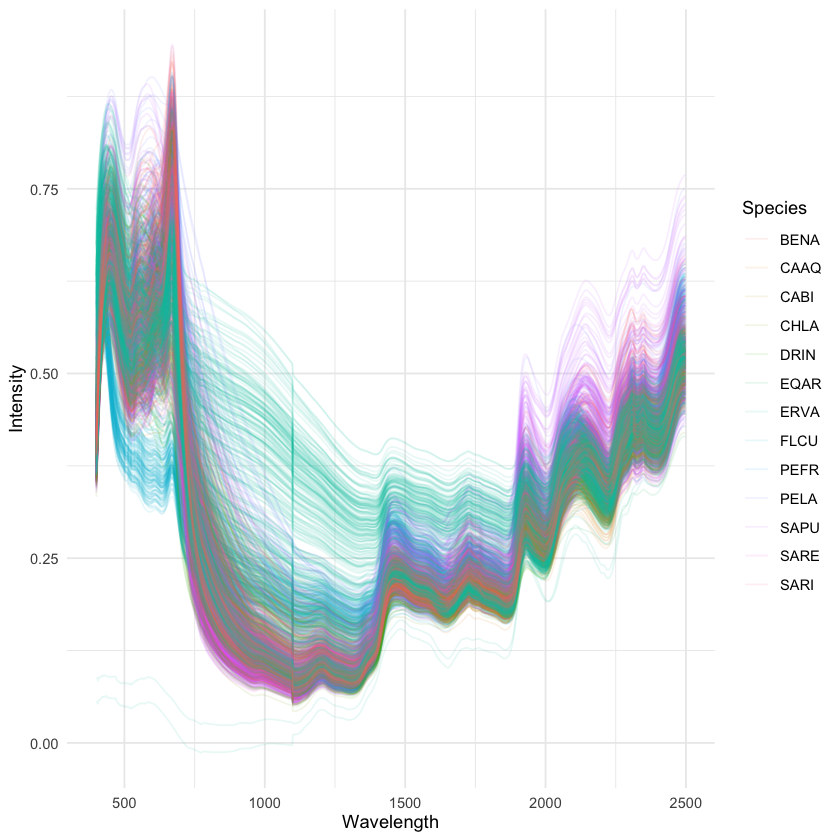

In [ ]:
ggplot(combined, aes(x = wavelength, y = intensity, group = sample_id, color = species)) +
  geom_line(alpha = 0.1) +
  labs(x = "Wavelength", y = "Intensity", color = "Species") +
  theme_minimal()

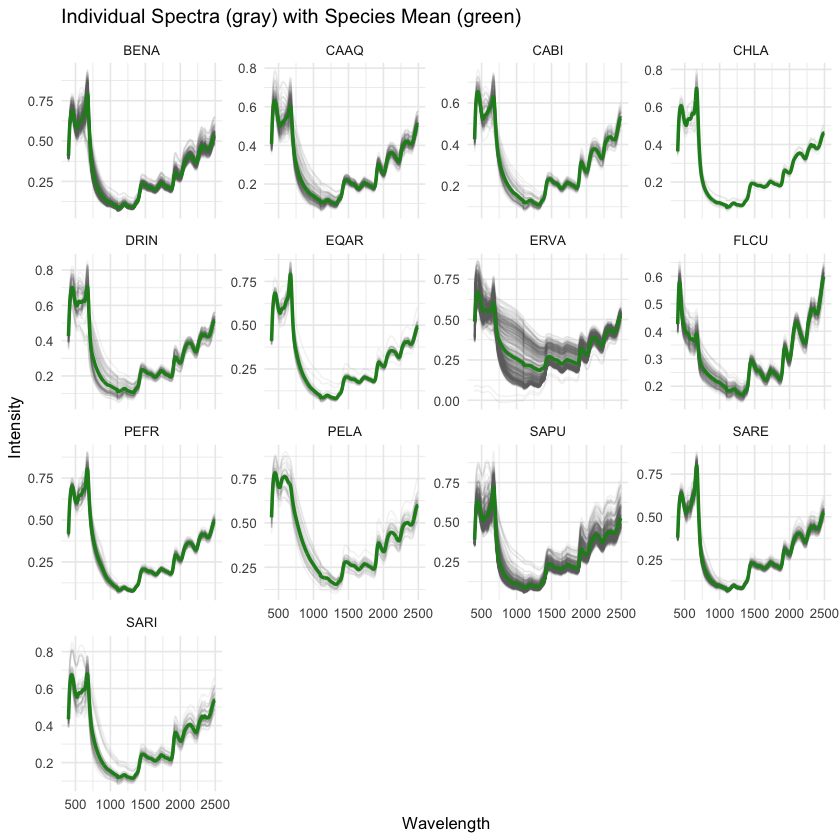

In [10]:
ggplot(combined, aes(x = wavelength, y = intensity, group = sample_id)) +
  geom_line(alpha = 0.08, color = "gray40") +
  geom_line(data = species_mean, aes(x = wavelength, y = mean_intensity, group = 1),
            color = "forestgreen", linewidth = 1) +
  facet_wrap(~ species, scales = "free_y") +
  labs(title = "Individual Spectra (gray) with Species Mean (green)",
       x = "Wavelength", y = "Intensity") +
  theme_minimal(base_size = 10)

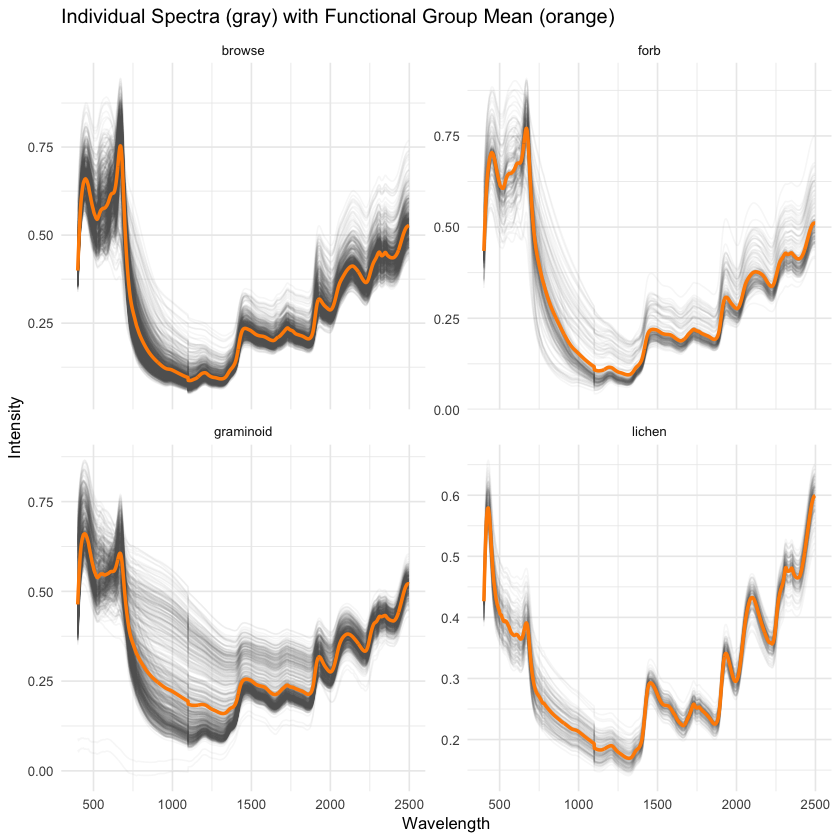

In [ ]:
# Mean spectrum per functional group
functional_group_mean <- combined %>%
  group_by(pfg, wavelength) %>%
  summarize(mean_intensity = mean(intensity, na.rm = TRUE), .groups = "drop")

ggplot(combined, aes(x = wavelength, y = intensity, group = sample_id)) +
  geom_line(alpha = 0.05, color = "gray40") +
  geom_line(data = functional_group_mean, aes(x = wavelength, y = mean_intensity, group = 1),
            color = "darkorange", linewidth = 1) +
  facet_wrap(~ pfg, scales = "free_y") +
  labs(title = "Individual Spectra (gray) with Functional Group Mean (orange)",
       x = "Wavelength", y = "Intensity") +
  theme_minimal(base_size = 10) # I like this minimal good.

In [1]:
# fix plot figures 
2+2

[1] 4